In [ ]:
#Step 1: Import Required Libraries
#the necessary libraries: pandas, numpy, tensorflow,
#matplotlib, wordcloud, nltk for data processing, model building, and visualization.



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [ ]:
import string
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud
nltk.download('stopwords')



[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

import warnings
warnings.filterwarnings('ignore')



In [ ]:
#Step 2: Load the Dataset
#We’ll use a dataset containing labeled emails (Spam or Ham).
#Let’s load the dataset and inspect its structure.
#You can download the dataset from here:




In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Share spam_ham_dataset.csv to Share spam_ham_dataset (3).csv


In [ ]:
data = pd.read_csv('Share spam_ham_dataset.csv')
data.head()


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\r\nthis deal is t...,0


In [ ]:
#This will give us a glimpse into the first few rows of the dataset. You can also check the shape of the dataset:


In [ ]:
data.shape


(5171, 4)

In [ ]:
#The data contains 5171 rows and four columns.



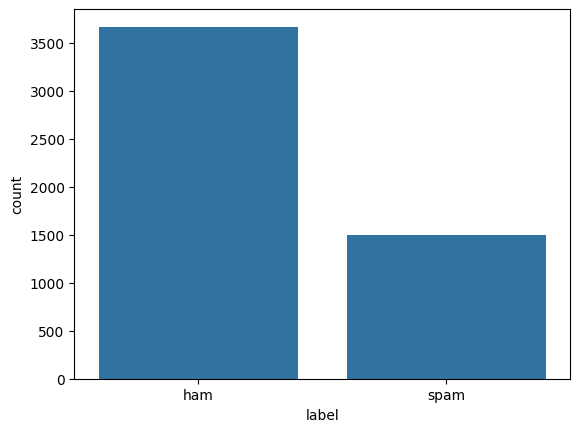

In [ ]:
#Now, let's visualize the label distribution to get understanding of the class distribution:
sns.countplot(x='label', data=data)
plt.show()



In [ ]:
#Step 3: Balance the Dataset
#We can clearly see that number of samples of Ham is much more than that of
#Spam which implies that the dataset we are using is imbalanced.
#To address the imbalance we’ll downsample the majority
#class (Ham) to match the minority class (Spam).



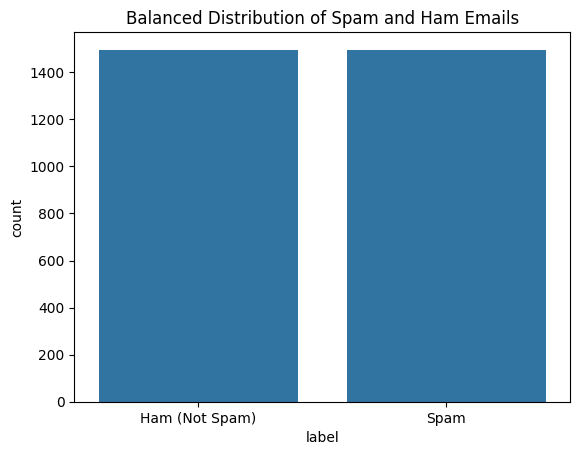

In [ ]:
ham_msg = data[data['label'] == 'ham']
spam_msg = data[data['label'] == 'spam']

# Downsample Ham emails to match the number of Spam emails
ham_msg_balanced = ham_msg.sample(n=len(spam_msg), random_state=42)

# Combine balanced data
balanced_data = pd.concat([ham_msg_balanced, spam_msg]).reset_index(drop=True)

# Visualize the balanced dataset
sns.countplot(x='label', data=balanced_data)
plt.title("Balanced Distribution of Spam and Ham Emails")
plt.xticks(ticks=[0, 1], labels=['Ham (Not Spam)', 'Spam'])
plt.show()


In [ ]:
#Step 4: Clean the Text
#Textual data often requires preprocessing before feeding it into a machine learning model.
#Common steps include removing stopwords, punctuations, and performing stemming/lemmatization.
#Although removing data means loss of information we need to do this to make
#the data perfect to feed into a machine learning model.




In [ ]:
balanced_data['text'] = balanced_data['text'].str.replace('Subject', '')
balanced_data.head()


,Unnamed: 0,label,text,label_num
0,83,ham,: buyback deals - - january 2000\r\nattached a...,0
1,3176,ham,: eastrans nomination change effective 5 / 3 /...,0
2,384,ham,: aquila header ( meter # 980072 ) - january v...,0
3,966,ham,": cilco\r\nper our conversation , the months r...",0
4,3157,ham,: re : nom / actual vol for april 26 th\r\nwe ...,0


In [ ]:
punctuations_list = string.punctuation
def remove_punctuations(text):
    temp = str.maketrans('', '', punctuations_list)
    return text.translate(temp)

balanced_data['text']= balanced_data['text'].apply(lambda x: remove_punctuations(x))
balanced_data.head()


,Unnamed: 0,label,text,label_num
0,83,ham,buyback deals january 2000\r\nattached are ...,0
1,3176,ham,eastrans nomination change effective 5 3 01...,0
2,384,ham,aquila header meter 980072 january volume...,0
3,966,ham,cilco\r\nper our conversation the months rel...,0
4,3157,ham,re nom actual vol for april 26 th\r\nwe agr...,0


In [ ]:
def remove_stopwords(text):
    stop_words = stopwords.words('english')

    imp_words = []

    # Storing the important words
    for word in (text).split():
       word = word.lower()

       if word not in stop_words:
            imp_words.append(word)

    output = " ".join(imp_words)

    return output


balanced_data['text'] = balanced_data['text'].apply(lambda text: remove_stopwords(text))
balanced_data.head()


,Unnamed: 0,label,text,label_num
0,83,ham,buyback deals january 2000 attached current bu...,0
1,3176,ham,eastrans nomination change effective 5 3 01 pl...,0
2,384,ham,aquila header meter 980072 january volumes dar...,0
3,966,ham,cilco per conversation months relating cilco d...,0
4,3157,ham,nom actual vol april 26 th agree eileen ponton...,0


In [ ]:
#Visualization Word Cloud
#A word cloud is a text visualization tool that help us to get
#insights into the most frequent words present in the corpus of the data.




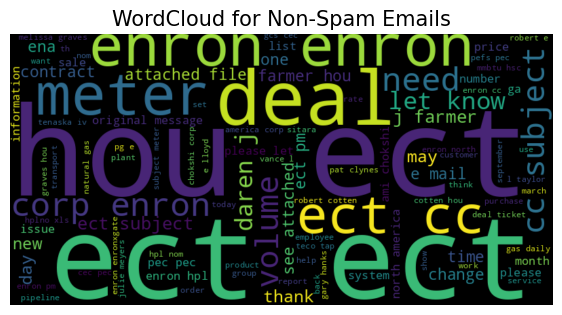

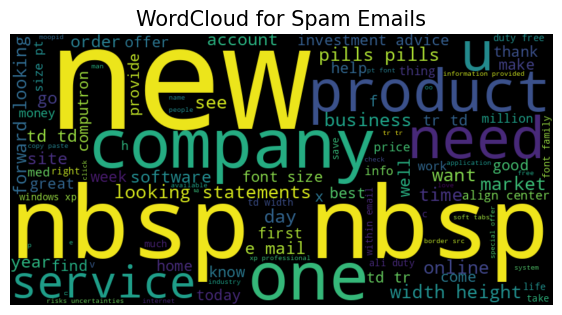

In [ ]:
def plot_word_cloud(data, typ):
    email_corpus = " ".join(data['text'])
    wc = WordCloud(background_color='black', max_words=100, width=800, height=400).generate(email_corpus)
    plt.figure(figsize=(7, 7))
    plt.imshow(wc, interpolation='bilinear')
    plt.title(f'WordCloud for {typ} Emails', fontsize=15)
    plt.axis('off')
    plt.show()

plot_word_cloud(balanced_data[balanced_data['label'] == 'ham'], typ='Non-Spam')
plot_word_cloud(balanced_data[balanced_data['label'] == 'spam'], typ='Spam')


In [ ]:
#Step 6: Tokenization and Padding
#Machine learning models work with numbers, so we need to convert
#the text data into numerical vectors using Tokenization and Padding.

#Tokenization: Converts each word into a unique integer.
#Padding: Ensures that all text sequences have
#the same length, making them compatible with the model.



In [ ]:
train_X, test_X, train_Y, test_Y = train_test_split(
    balanced_data['text'], balanced_data['label'], test_size=0.2, random_state=42
)

tokenizer = Tokenizer()
tokenizer.fit_on_texts(train_X)

train_sequences = tokenizer.texts_to_sequences(train_X)
test_sequences = tokenizer.texts_to_sequences(test_X)

max_len = 100  # Maximum sequence length
train_sequences = pad_sequences(train_sequences, maxlen=max_len, padding='post', truncating='post')
test_sequences = pad_sequences(test_sequences, maxlen=max_len, padding='post', truncating='post')

train_Y = (train_Y == 'spam').astype(int)
test_Y = (test_Y == 'spam').astype(int)


In [ ]:
#Step 7: Define the Model
#We will build a deep learning model using a Sequential architecture.
#This model will include:

#Embedding Layer: Learns vector representations of words.
#LSTM Layer: Captures patterns in sequences.
#Fully Connected Layer: Extracts relevant features.
#Output Layer: Predicts whether an email is spam or not.


In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Embedding(input_dim=len(tokenizer.word_index) + 1, output_dim=32, input_length=max_len),
    tf.keras.layers.LSTM(16),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')  # Output layer
])

model.compile(
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Step 8: Train the Model
#We train the model using EarlyStopping and ReduceLROnPlateau callbacks.
#These callbacks help stop the training early if the model’s performance
#doesn’t improve and reduce the learning rate to fine-tune the model.


In [ ]:
es = EarlyStopping(patience=3, monitor='val_accuracy', restore_best_weights=True)
lr = ReduceLROnPlateau(patience=2, monitor='val_loss', factor=0.5, verbose=0)

history = model.fit(
    train_sequences, train_Y,
    validation_data=(test_sequences, test_Y),
    epochs=20,
    batch_size=32,
    callbacks=[lr, es]
)


Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.5182 - loss: 0.6879 - val_accuracy: 0.6144 - val_loss: 0.6313 - learning_rate: 0.0010
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.8939 - loss: 0.3249 - val_accuracy: 0.9449 - val_loss: 0.2150 - learning_rate: 0.0010
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.9473 - loss: 0.2126 - val_accuracy: 0.8915 - val_loss: 0.3777 - learning_rate: 0.0010
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.9365 - loss: 0.2311 - val_accuracy: 0.9683 - val_loss: 0.1740 - learning_rate: 0.0010
Epoch 5/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 6s 52ms/step - accuracy: 0.9636 - loss: 0.1504 - val_accuracy: 0.8881 - val_loss: 0.3690 - learning_rate: 0.0010
Epoch 6/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.8972 - loss: 0.2906 - val_accuracy: 0.8548 - val_loss: 0.3728 - learning_rate: 0.0010
Epoch 7/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.8951 - loss: 0.2810 - val_acc

In [ ]:
#After training, we evaluate the model on the test data to measure its performance.

test_loss, test_accuracy = model.evaluate(test_sequences, test_Y)
print('Test Loss :',test_loss)
print('Test Accuracy :',test_accuracy)


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9683 - loss: 0.1740
Test Loss : 0.17403589189052582
Test Accuracy : 0.9682804942131042


In [ ]:
#Thus, the training accuracy turns out to be 97% which is quite satisfactory.
#Having trained our model, we can plot a graph depicting the variance of training and validation accuracies with the no. of epochs.



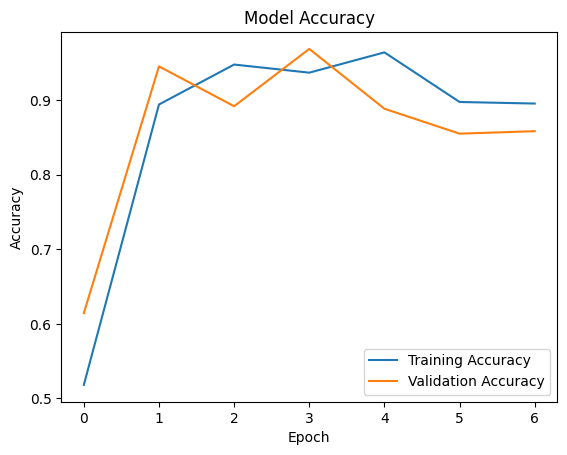

In [ ]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()


In [ ]:
#By following these steps, we have successfully built a machine
#learning model that can classify emails as spam or ham.
#With further optimization, this model can be fine-tuned to
#improve its performance even more.

